# Sesión 3 · Lab: el lenguaje como probabilidad
**Herramientas para el Procesamiento de Lenguaje Natural**

---
## Parte 0 · Corpus, entrenamiento y prueba

In [20]:
import re, math, random, importlib, subprocess, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

rng = np.random.default_rng(42)
random.seed(42)
print("Listo ✔")

Listo ✔


In [19]:
LIBROS = {"Cervantes": 2000, "Galdós": 17340, "Pardo Bazán": 18005, "Quiroga": 13507}
COLORES = {"Cervantes": "#14B8A6", "Galdós": "#FFB020", "Pardo Bazán": "#FF6B6B", "Quiroga": "#6C4FF6"}
CARPETA = Path("corpus"); CARPETA.mkdir(exist_ok=True)

def quitar_encabezado_gutenberg(t):
    a = re.search(r"\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", t, re.I | re.S)
    b = re.search(r"\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK", t, re.I)
    return t[(a.end() if a else 0):(b.start() if b else len(t))].strip()

def descargar_libro(i):
    f = CARPETA / f"pg{i}.txt"
    if not f.exists():
        for url in [f"https://www.gutenberg.org/cache/epub/{i}/pg{i}.txt", f"https://www.gutenberg.org/files/{i}/{i}-0.txt"]:
            try:
                r = requests.get(url, timeout=30)
                if r.status_code == 200:
                    f.write_bytes(r.content); break
            except requests.RequestException:
                pass
        else:
            raise RuntimeError(f"No pude descargar {i}. Sube corpus/pg{i}.txt a mano.")
    return quitar_encabezado_gutenberg(f.read_bytes().decode("utf-8", errors="replace"))

textos = {a: descargar_libro(i) for a, i in LIBROS.items()}

def tokens_de(texto):
    return re.findall(r"[a-záéíóúüñ]+", texto.lower())

def oraciones_de(texto):
    return [tokens_de(o) for o in re.split(r"[.!?;:]+", texto) if len(tokens_de(o)) > 2]

# Reparto: el primer 80% de las oraciones de cada autor para entrenar, el último 20% para probar
oraciones = {a: oraciones_de(t) for a, t in textos.items()}
entrena, prueba = {}, {}
for a, sents in oraciones.items():
    corte = int(len(sents) * 0.8)
    entrena[a], prueba[a] = sents[:corte], sents[corte:]

pd.DataFrame({a: {"oraciones entrena": len(entrena[a]), "oraciones prueba": len(prueba[a]),
                  "palabras entrena": sum(map(len, entrena[a]))} for a in LIBROS}).T

,oraciones entrena,oraciones prueba,palabras entrena
Cervantes,12859,3215,311781
Galdós,3114,779,40985
Pardo Bazán,4218,1055,66149
Quiroga,3081,771,40253


💬 ¿Por qué probamos con la **última parte** del libro y no con oraciones al azar? Si el modelo vio oraciones vecinas en el entrenamiento, la prueba sería demasiado fácil. Ojo: aun así es **la misma obra**; el ideal para el proyecto es probar con **otra obra** del autor.

---
## Parte 1 · El juego de Shannon con la computadora

En clase adivinamos letras. Ahora la computadora lo hace: estima cuántos **bits por letra** necesita para adivinar la siguiente, mirando las últimas *k* letras.

$$H_k = -\frac{1}{N}\sum \log_2 P(\text{letra} \mid \text{las } k \text{ letras anteriores})$$

Si adivinara al azar entre 33 símbolos: 5.04 bits por letra

mirando 0 letras atrás: 4.09 bits por letra
mirando 1 letras atrás: 3.14 bits por letra
mirando 2 letras atrás: 2.67 bits por letra
mirando 3 letras atrás: 2.28 bits por letra
mirando 4 letras atrás: 2.11 bits por letra
mirando 5 letras atrás: 2.21 bits por letra
mirando 6 letras atrás: 2.54 bits por letra


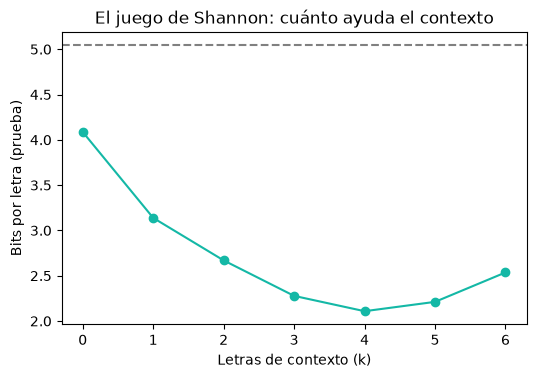

In [21]:
def solo_letras(t):
    return re.sub(r"[^a-záéíóúüñ ]+", " ", t.lower()).replace("\n", " ")

def limpiar_espacios(t):
    return re.sub(r" +", " ", t)

txt = limpiar_espacios(solo_letras(textos["Cervantes"]))
corte = int(len(txt) * 0.8)
entr_c, prue_c = txt[:corte][:600_000], txt[corte:][:100_000]
alfabeto = sorted(set(entr_c) | set(prue_c))
A = len(alfabeto)

def entropia_caracter(k, alpha=0.05):
    ctx = defaultdict(Counter)
    for i in range(k, len(entr_c)):
        ctx[entr_c[i - k:i]][entr_c[i]] += 1
    bits = 0.0; n = 0
    for i in range(k, len(prue_c)):
        c = ctx.get(prue_c[i - k:i])
        tot = sum(c.values()) if c else 0
        p = ((c[prue_c[i]] if c else 0) + alpha) / (tot + alpha * A)
        bits -= math.log2(p); n += 1
    return bits / n

ks = list(range(0, 7))
H = [entropia_caracter(k) for k in ks]
print(f"Si adivinara al azar entre {A} símbolos: {math.log2(A):.2f} bits por letra\n")
for k, h in zip(ks, H): print(f"mirando {k} letras atrás: {h:.2f} bits por letra")

plt.figure(figsize=(6, 3.8))
plt.plot(ks, H, marker="o", color="#14B8A6"); plt.axhline(math.log2(A), ls="--", color="gray")
plt.xlabel("Letras de contexto (k)"); plt.ylabel("Bits por letra (prueba)")
plt.title("El juego de Shannon: cuánto ayuda el contexto"); plt.show()

💬 La curva **baja** y luego **vuelve a subir**. ¿Por qué más contexto empeora el resultado a partir de cierto *k*? (Pista: piensen en la tabla de la clase: ¿cuántos contextos de 6 letras se vieron en el entrenamiento?) Ese es el problema de los ceros, ahora con letras.

---
## Parte 2 · Bigramas desde cero, conteos y generación

Estimación por conteo: **P(w | v) = C(v w) ÷ C(v)**. Añadimos marcadores `<s>` (inicio) y `</s>` (fin) a cada oración.

In [22]:
INI, FIN, UNK = "<s>", "</s>", "<unk>"

def contar_bigramas(sents):
    big = defaultdict(Counter)
    for s in sents:
        t = [INI] + s + [FIN]
        for v, w in zip(t, t[1:]):
            big[v][w] += 1
    return big

bg = contar_bigramas(entrena["Cervantes"])

def p_mv(w, v, big=bg):
    tot = sum(big[v].values())
    return big[v][w] / tot if tot else 0.0

def top_siguientes(v, k=8, big=bg):
    tot = sum(big[v].values())
    return [(w, round(c / tot, 3)) for w, c in big[v].most_common(k)]

for v in ["el", "don", "sancho", "que"]:
    if v in bg:
        print(f"Después de «{v}»:", top_siguientes(v))

Después de «el»: [('que', 0.036), ('cura', 0.034), ('cual', 0.033), ('mundo', 0.027), ('de', 0.02), ('barbero', 0.017), ('cielo', 0.016), ('duque', 0.013)]
Después de «don»: [('quijote', 0.839), ('fernando', 0.064), ('luis', 0.018), ('diego', 0.013), ('lorenzo', 0.01), ('gaiferos', 0.006), ('que', 0.005), ('belianís', 0.003)]
Después de «sancho»: [('panza', 0.138), ('que', 0.135), ('</s>', 0.126), ('y', 0.063), ('dijo', 0.045), ('respondió', 0.026), ('a', 0.025), ('no', 0.02)]
Después de «que»: [('no', 0.062), ('se', 0.042), ('le', 0.033), ('el', 0.031), ('en', 0.031), ('me', 0.027), ('yo', 0.027), ('la', 0.025)]


In [23]:
def generar_bigrama(big, max_palabras=25, semilla=None):
    r = random.Random(semilla)
    v, out = INI, []
    for _ in range(max_palabras):
        cand = big[v]
        w = r.choices(list(cand), weights=cand.values())[0]
        if w == FIN: break
        out.append(w); v = w
    return " ".join(out)

for i in range(4):
    print(f"{i + 1}. {generar_bigrama(bg, semilla=i)}")

1. págueseme lo que no sin responder sino de aquí como debe de los descuidos de los palacios de tormento quiere dar tantos encuentros dieron respondió
2. y presentes he dicho no será justo como lo que trabajan tanto contento
3. dulcinea tiene a la tuya si lo que estaba guardada para le sirvió de arriba cosa fácil y aun hasta entonces le he de sancho
4. en fin de miedo estoy por su entereza y nos sienta y pasado en ellas tocantes a ensillar a moverse a la revuelta la cuenta


💬 ¿Suena a Cervantes? ¿Cuántas palabras seguidas tienen sentido antes de que se pierda? Compárenlo con la idea de Shannon de 1948: él lo hacía a mano con un libro.

---
## Parte 3 · Ceros y Laplace

**Problema:** ¿qué fracción de los bigramas de **prueba** nunca apareció en el entrenamiento?

In [24]:
def fraccion_no_vista(autor):
    big = contar_bigramas(entrena[autor])
    vistos = {(v, w) for v, c in big.items() for w in c}
    total = nuevos = 0
    for s in prueba[autor]:
        t = [INI] + s + [FIN]
        for par in zip(t, t[1:]):
            total += 1; nuevos += par not in vistos
    return nuevos / total

print("Bigramas de prueba que nunca se vieron en el entrenamiento:")
for a in LIBROS: print(f"  {a:12s} {fraccion_no_vista(a):.1%}")

Bigramas de prueba que nunca se vieron en el entrenamiento:
  Cervantes    31.5%
  Galdós       51.4%
  Pardo Bazán  55.5%
  Quiroga      52.9%


**Solución 1 · Laplace (sumar uno):** P(w | v) = (C(v w) + 1) ÷ (C(v) + V). Veamos qué pasa con la probabilidad.

In [25]:
V_c = len({w for s in entrena["Cervantes"] for w in s} | {FIN})   # tamaño del vocabulario

def p_laplace(w, v, big=bg, V=V_c, k=1.0):
    tot = sum(big[v].values())
    return (big[v][w] + k) / (tot + k * V)

for v in ["el", "de", "que"]:
    tot = sum(bg[v].values()); tipos = len(bg[v])
    masa_no_vista = (V_c - tipos) * 1 / (tot + V_c)
    print(f"Contexto «{v}»: visto {tot} veces con {tipos} continuaciones distintas → "
          f"con Laplace, {masa_no_vista:.1%} de la probabilidad se va a palabras que NUNCA vimos después de «{v}»")

Contexto «el»: visto 6688 veces con 1265 continuaciones distintas → con Laplace, 70.8% de la probabilidad se va a palabras que NUNCA vimos después de «el»
Contexto «de»: visto 15069 veces con 2598 continuaciones distintas → con Laplace, 50.4% de la probabilidad se va a palabras que NUNCA vimos después de «de»
Contexto «que»: visto 17178 veces con 2101 continuaciones distintas → con Laplace, 48.9% de la probabilidad se va a palabras que NUNCA vimos después de «que»


💬 **Segundo problema de la solución:** Laplace le quita casi toda la probabilidad a lo que sí vimos. ¿Qué pasa si en vez de sumar **1** sumamos un número más chico (por ejemplo 0.01)? Lo probamos en la Parte 4.

---
## Parte 4 · Perplejidad y Kneser-Ney desde cero

**Perplejidad:** la entropía convertida a "entre cuántas palabras duda el modelo": $PP = 2^{H}$ con $H = -\frac{1}{N}\sum \log_2 P(w_i \mid \text{contexto})$. **Menos es mejor.**

Para que las perplejidades sean **comparables entre autores**, usamos un **vocabulario común**: las palabras que aparecen al menos 3 veces en el entrenamiento de todos los autores; el resto se vuelve `<unk>`.

In [26]:
def construir_vocab(entrena_dict, min_c=3, excluir=frozenset()):
    c = Counter(w for sents in entrena_dict.values() for s in sents for w in s)
    return {w for w, n in c.items() if n >= min_c and w not in excluir}

def mapear(sents, vocab):
    return [[w if w in vocab else UNK for w in s] for s in sents]

VOCAB = construir_vocab(entrena)
print(f"Vocabulario común: {len(VOCAB):,} palabras")

E = {a: mapear(entrena[a], VOCAB) for a in LIBROS}
P = {a: mapear(prueba[a], VOCAB) for a in LIBROS}
print("Palabras desconocidas en la prueba de Cervantes:",
      f"{sum(w == UNK for s in P['Cervantes'] for w in s) / sum(map(len, P['Cervantes'])):.1%}")

Vocabulario común: 11,045 palabras
Palabras desconocidas en la prueba de Cervantes: 6.6%


Ahora el modelo de **Kneser-Ney interpolado** para n-gramas de cualquier orden. Recuerda la idea: se **resta un descuento d** a cada conteo, y lo restado se reparte según la **probabilidad de continuación** de un orden más corto (cuántos contextos distintos tiene la palabra).

In [27]:
class KneserNey:
    # n-gramas con suavizado de Kneser-Ney interpolado (descuento fijo d)
    def __init__(self, sents, n=3, d=0.75):
        self.n, self.d = n, d
        self.tabla = {m: Counter() for m in range(1, n + 1)}      # tabla[m][ngrama de largo m] = conteo
        for s in sents:
            t = [INI] * (n - 1) + s + [FIN]
            for i in range(n - 1, len(t)):
                self.tabla[n][tuple(t[i - n + 1:i + 1])] += 1
        # órdenes menores: conteos de continuación = en cuántos contextos distintos aparece
        for m in range(n - 1, 0, -1):
            for g in self.tabla[m + 1]:
                self.tabla[m][g[1:]] += 1
        # por contexto: total y número de continuaciones distintas
        self.total = {m: Counter() for m in range(1, n + 1)}
        self.tipos = {m: Counter() for m in range(1, n + 1)}
        for m in range(1, n + 1):
            for g, c in self.tabla[m].items():
                self.total[m][g[:-1]] += c; self.tipos[m][g[:-1]] += 1
        self.V = len(self.tabla[1])

    def prob(self, w, ctx, m=None):
        m = m or self.n
        ctx = tuple(ctx[-(m - 1):]) if m > 1 else ()
        tot = self.total[m].get(ctx, 0)
        if m == 1:   # base: distribución de continuación con una pizca uniforme
            c = self.tabla[1].get((w,), 0)
            return max(c - self.d, 0) / tot + self.d * self.tipos[1][()] / tot / self.V
        if tot == 0:                       # contexto nunca visto: bajar de orden
            return self.prob(w, ctx, m - 1)
        c = self.tabla[m].get(ctx + (w,), 0)
        lam = self.d * self.tipos[m][ctx] / tot
        return max(c - self.d, 0) / tot + lam * self.prob(w, ctx, m - 1)

def perplejidad(modelo_prob, sents, n):
    # modelo_prob(w, ctx) -> P. Contexto con n-1 marcadores <s> al inicio de cada oración
    bits = N = 0
    for s in sents:
        t = [INI] * (n - 1) + s + [FIN]
        for i in range(n - 1, len(t)):
            bits -= math.log2(modelo_prob(t[i], t[i - n + 1:i])); N += 1
    return 2 ** (bits / N)

print("Clase KneserNey lista ✔")

Clase KneserNey lista ✔


Unigrama (+1)                   417.4
Bigrama + Laplace (k = 1)       898.0
Bigrama + Laplace (k = 0.1)     391.3
Bigrama + Laplace (k = 0.01)    275.7
Bigrama + Kneser-Ney            159.8
Trigrama + Kneser-Ney           142.5


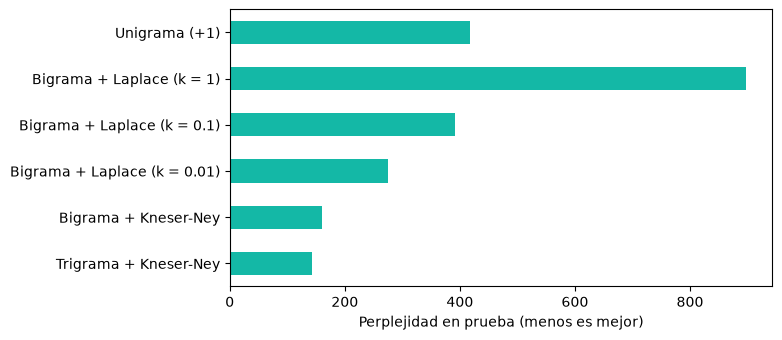

In [28]:
# Comparación en Cervantes (prueba reducida para que sea rápido)
prueba_c = P["Cervantes"][:1500]
ent_c = E["Cervantes"]

# Unigrama y Laplace sobre bigramas (con el mismo vocabulario)
uni = Counter(w for s in ent_c for w in s + [FIN]); N_uni = sum(uni.values()); V = len(uni)
bgE = contar_bigramas(ent_c)

def p_uni(w, ctx): return (uni[w] + 1) / (N_uni + V)
def p_lap(k):
    return lambda w, ctx: (bgE[ctx[-1]][w] + k) / (sum(bgE[ctx[-1]].values()) + k * V)

resultados = {
    "Unigrama (+1)": perplejidad(p_uni, prueba_c, 2),
    "Bigrama + Laplace (k = 1)": perplejidad(p_lap(1.0), prueba_c, 2),
    "Bigrama + Laplace (k = 0.1)": perplejidad(p_lap(0.1), prueba_c, 2),
    "Bigrama + Laplace (k = 0.01)": perplejidad(p_lap(0.01), prueba_c, 2),
}
kn2 = KneserNey(ent_c, n=2); resultados["Bigrama + Kneser-Ney"] = perplejidad(kn2.prob, prueba_c, 2)
kn3 = KneserNey(ent_c, n=3); resultados["Trigrama + Kneser-Ney"] = perplejidad(kn3.prob, prueba_c, 3)

serie = pd.Series(resultados, name="perplejidad").round(1)
print(serie.to_string())
serie[::-1].plot.barh(color="#14B8A6", figsize=(7, 3.6)); plt.xlabel("Perplejidad en prueba (menos es mejor)"); plt.show()

💬 ¿Cuál es mejor, Laplace con k = 1 o con k = 0.01? ¿Y Kneser-Ney? ¿Qué pasó al pasar de bigrama a trigrama? Si el trigrama no mejora tanto, piensen en la fracción de bigramas no vistos de la Parte 3: con trigramas es todavía más grande.

---
## Parte 5 · Avance 3: un modelo de lenguaje por autor

**Idea:** entrenamos un modelo por autor. Para un fragmento nuevo, calculamos su perplejidad con cada modelo y **gana el autor cuyo modelo se sorprende menos**.

Los fragmentos de prueba son de ~200 palabras, tomados de la **parte de prueba** de cada libro.

In [29]:
modelos = {a: KneserNey(E[a], n=3) for a in LIBROS}

def fragmentos_prueba(autor, n_palabras=200, maximo=30):
    frs, actual, cuenta = [], [], 0
    for s in P[autor]:
        actual.append(s); cuenta += len(s)
        if cuenta >= n_palabras:
            frs.append(actual); actual, cuenta = [], 0
    return frs[:maximo]

FR = {a: fragmentos_prueba(a) for a in LIBROS}
print({a: len(f) for a, f in FR.items()}, "fragmentos de prueba por autor")

def clasificar(frag, modelos):
    pp = {a: perplejidad(m.prob, frag, 3) for a, m in modelos.items()}
    return min(pp, key=pp.get), pp

def evaluar(modelos, FR):
    etiquetas = list(LIBROS)
    M = pd.DataFrame(0, index=etiquetas, columns=etiquetas)
    for real, frs in FR.items():
        for fr in frs:
            M.loc[real, clasificar(fr, modelos)[0]] += 1
    return M, np.trace(M.values) / M.values.sum()

M, exactitud = evaluar(modelos, FR)
print(f"\nExactitud de la atribución por perplejidad: {exactitud:.1%}\n")
M

{'Cervantes': 30, 'Galdós': 30, 'Pardo Bazán': 30, 'Quiroga': 30} fragmentos de prueba por autor

Exactitud de la atribución por perplejidad: 99.2%



,Cervantes,Galdós,Pardo Bazán,Quiroga
Cervantes,30,0,0,0
Galdós,0,30,0,0
Pardo Bazán,0,0,30,0
Quiroga,1,0,0,29


Dos preguntas de control, como en las sesiones anteriores:

1. **¿Cuánto se debe a los nombres propios?** Quitamos los nombres propios del vocabulario (se vuelven `<unk>`) y repetimos.
2. **¿Cómo nos va frente a TF-IDF?** Entrenamos TF-IDF + regresión logística sobre los mismos fragmentos.

In [30]:
# 1. Sin nombres propios (misma idea de la sesión 2: palabras que casi siempre aparecen con mayúscula)
mayus = Counter(); total = Counter()
for t in textos.values():
    for w in re.findall(r"[A-Za-zÁÉÍÓÚÜÑáéíóúüñ]+", t):
        total[w.lower()] += 1
        if w[0].isupper(): mayus[w.lower()] += 1
PROPIOS = {w for w, c in total.items() if c >= 5 and mayus[w] / c > 0.9}
print(f"{len(PROPIOS)} posibles nombres propios")

VOCAB_SP = construir_vocab(entrena, excluir=PROPIOS)
E_sp = {a: mapear(entrena[a], VOCAB_SP) for a in LIBROS}
P_sp = {a: mapear(prueba[a], VOCAB_SP) for a in LIBROS}
modelos_sp = {a: KneserNey(E_sp[a], n=3) for a in LIBROS}

P_backup = P
P = P_sp
FR_sp = {a: fragmentos_prueba(a) for a in LIBROS}
P = P_backup
_, exactitud_sp = evaluar(modelos_sp, FR_sp)
print(f"Exactitud sin nombres propios: {exactitud_sp:.1%}  (con ellos: {exactitud:.1%})")

331 posibles nombres propios
Exactitud sin nombres propios: 96.7%  (con ellos: 99.2%)


In [31]:
# 2. Línea base: TF-IDF + regresión logística con fragmentos del entrenamiento
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def trozos(sents_lista, n=200):
    frs, act, c = [], [], 0
    for s in sents_lista:
        act += s; c += len(s)
        if c >= n: frs.append(act); act, c = [], 0
    return frs

Xtr, ytr = [], []
for a in LIBROS:
    frs = trozos(E[a])[:150]
    Xtr += frs; ytr += [a] * len(frs)
Xte, yte = [], []
for a in LIBROS:
    for fr in FR[a]:
        Xte.append([w for s in fr for w in s]); yte.append(a)

base = make_pipeline(TfidfVectorizer(analyzer=lambda d: d, min_df=2), LogisticRegression(max_iter=2000))
base.fit(Xtr, ytr)
print(f"TF-IDF + regresión logística: {np.mean(base.predict(Xte) == np.array(yte)):.1%}")
print(f"Perplejidad (trigrama + Kneser-Ney): {exactitud:.1%}")

TF-IDF + regresión logística: 91.7%
Perplejidad (trigrama + Kneser-Ney): 99.2%


💬 ¿Qué método gana? ¿Cambió mucho al quitar los nombres propios? Si cambia mucho, el modelo estaba reconociendo **el libro** y no **el estilo**. Para su proyecto: repitan esto con **una obra distinta** del mismo autor para probar.

⭐ **Para el Avance 3 con su corpus:** entrenen un modelo por autor, calculen la exactitud con y sin nombres propios y comparen contra el Delta (sesión 1) y TF-IDF (sesión 2).

---
## Parte 6 · Generar texto "a la manera de" cada autor

Para generar, muestreamos la siguiente palabra. Usamos el **trigrama más largo que se haya visto** (con *backoff*: si ese contexto no existe, bajamos a bigrama y a unigrama). La **temperatura** controla el riesgo: baja repite lo más probable; alta se vuelve caótica.

In [32]:
def construir_tablas(sents):
    tri, bi, uni_ = defaultdict(Counter), defaultdict(Counter), Counter()
    for s in sents:
        t = [INI, INI] + s + [FIN]
        for i in range(2, len(t)):
            tri[(t[i - 2], t[i - 1])][t[i]] += 1
            bi[t[i - 1]][t[i]] += 1
            uni_[t[i]] += 1
    return tri, bi, uni_

TABLAS = {a: construir_tablas(E[a]) for a in LIBROS}

def siguiente(tablas, a, b, r, T=0.8):
    tri, bi, uni_ = tablas
    for cand in (tri.get((a, b)), bi.get(b), uni_):          # backoff: trigrama → bigrama → unigrama
        ws = [w for w in (cand or {}) if w != UNK]
        if ws: break
    pesos = [cand[w] ** (1 / T) for w in ws]
    return r.choices(ws, weights=pesos)[0]

def generar(autor, max_palabras=30, T=0.8, semilla=0):
    r = random.Random(semilla); a, b, out = INI, INI, []
    for _ in range(max_palabras):
        w = siguiente(TABLAS[autor], a, b, r, T)
        if w == FIN: break
        out.append(w); a, b = b, w
    return " ".join(out)

for autor in LIBROS:
    print(f"\n● {autor}")
    for i in range(2): print("  ", generar(autor, semilla=i))


● Cervantes
   viendo lo cual se dio a mi señor licenciado respondió
   y esto no se le dio cuenta de la mancha llamado por otro nombre el caballero de damas tan bien como aquellos de cuyos nombres jamás la dije a un

● Galdós
   quiero echarla de mí
   me enfado con papá cuando le vio en camino tomó el que tan cerca de zarzas las más bonitas y crecidas de todo lo que yo soy hermano de d

● Pardo Bazán
   don eugenio sacando un pañuelo de algodón a cuadros se cumplía el misterio
   los ojos no pudo menos de hacerle gracia el atavío de la virgen

● Quiroga
   cayó a lo de arrizabalaga
   pero de todos modos una hora antes acababan de perseguir a un lado


💬 Prueben `T = 0.3` y `T = 1.5`. ¿Qué pasa? Y la pregunta de fondo: ¿por qué un trigrama **no puede** escribir una oración larga con sentido? (Pista: la ventana es de solo 2 palabras.)

**Prueba rápida de autoría:** peguen una frase generada por un modelo en `clasificar(...)` y vean si el modelo de ese mismo autor es el que más la prefiere.

In [33]:
frase = generar("Galdós", max_palabras=40, semilla=7).split()
quien, pp = clasificar([frase], modelos)
print("Frase generada por el modelo de Galdós:\n ", " ".join(frase))
print("\nPerplejidad con cada modelo:", {a: round(v, 1) for a, v in pp.items()})
print("Gana:", quien)

Frase generada por el modelo de Galdós:
  la nela no respondió porque estaba su alma con supersticiones y cálculos y más vueltas como una salvaje

Perplejidad con cada modelo: {'Cervantes': 1281.1, 'Galdós': 6.9, 'Pardo Bazán': 790.1, 'Quiroga': 770.9}
Gana: Galdós


---
## Parte 7 · Una red neuronal (Bengio, 2003) contra los n-gramas

Los n-gramas no saben que *gato* y *perro* se parecen. Bengio propone aprender **a la vez** un vector por palabra y la función que predice la siguiente a partir de las 2 anteriores (el mismo contexto de un trigrama).

Para que la comparación sea justa: mismo vocabulario (las palabras con al menos 5 apariciones en Cervantes), mismo texto de entrenamiento y de prueba.

In [34]:
import torch, torch.nn as nn
torch.manual_seed(0)

cont = Counter(w for s in entrena["Cervantes"] for w in s)
VOC7 = {w for w, c in cont.items() if c >= 5}
itos = [UNK, INI, FIN] + sorted(VOC7)
stoi = {w: i for i, w in enumerate(itos)}
V7 = len(itos); print(f"Vocabulario de la red: {V7:,} palabras")

def a_ids(sents):
    X, y = [], []
    for s in sents:
        t = [INI, INI] + [w if w in VOC7 else UNK for w in s] + [FIN]
        for i in range(2, len(t)):
            X.append([stoi[t[i - 2]], stoi[t[i - 1]]]); y.append(stoi[t[i]])
    return torch.tensor(X), torch.tensor(y)

Xtr7, ytr7 = a_ids(entrena["Cervantes"][:12000])
Xte7, yte7 = a_ids(prueba["Cervantes"][:1500])
print(f"Ejemplos de entrenamiento: {len(ytr7):,} · de prueba: {len(yte7):,}")

Vocabulario de la red: 4,558 palabras
Ejemplos de entrenamiento: 303,588 · de prueba: 35,427


In [35]:
class LMNeuronal(nn.Module):
    def __init__(self, V, dim=48, oculta=128):
        super().__init__()
        self.emb = nn.Embedding(V, dim)              # un vector por palabra, compartido entre posiciones
        self.oculta = nn.Linear(2 * dim, oculta)     # concatena los 2 vectores del contexto
        self.salida = nn.Linear(oculta, V)           # una puntuación por cada palabra del vocabulario
    def forward(self, x):
        e = self.emb(x).flatten(1)
        return self.salida(torch.tanh(self.oculta(e)))

red = LMNeuronal(V7)
opt = torch.optim.Adam(red.parameters(), lr=3e-3)
perdida = nn.CrossEntropyLoss()

def perplejidad_red(X, y):
    red.eval()
    with torch.no_grad():
        return math.exp(perdida(red(X), y).item())

historial = []
for epoca in range(3):
    red.train()
    orden = torch.randperm(len(ytr7))
    for i in range(0, len(orden), 512):
        idx = orden[i:i + 512]
        opt.zero_grad(); loss = perdida(red(Xtr7[idx]), ytr7[idx]); loss.backward(); opt.step()
    historial.append(perplejidad_red(Xte7, yte7))
    print(f"época {epoca + 1}: perplejidad en prueba = {historial[-1]:.1f}")

época 1: perplejidad en prueba = 132.3
época 2: perplejidad en prueba = 118.7
época 3: perplejidad en prueba = 116.0


In [36]:
# Los n-gramas con el MISMO vocabulario y los mismos textos
ent7 = [[w if w in VOC7 else UNK for w in s] for s in entrena["Cervantes"][:12000]]
pru7 = [[w if w in VOC7 else UNK for w in s] for s in prueba["Cervantes"][:1500]]
kn7 = KneserNey(ent7, n=3)
pp_kn = perplejidad(kn7.prob, pru7, 3)

print(f"Trigrama + Kneser-Ney: {pp_kn:.1f}")
print(f"Red neuronal (2 palabras de contexto): {historial[-1]:.1f}")

# Vecinos en el espacio de vectores aprendido
def vecinos(palabra, k=6):
    E_ = red.emb.weight.detach(); E_ = E_ / E_.norm(dim=1, keepdim=True)
    sim = E_ @ E_[stoi[palabra]]
    return [itos[i] for i in sim.argsort(descending=True)[1:k + 1]]

for p in [w for w in ["rey", "caballero", "mujer", "ciudad"] if w in stoi]:
    print(f"vecinos de «{p}»:", vecinos(p))

Trigrama + Kneser-Ney: 104.9
Red neuronal (2 palabras de contexto): 116.0
vecinos de «rey»: ['escudo', 'rogar', 'impresas', 'pastores', 'fuesen', 'oí']
vecinos de «caballero»: ['hallamos', 'sobremanera', 'darse', 'propria', 'primo', 'ganancia']
vecinos de «mujer»: ['hermosura', 'riberas', 'barco', 'hombres', 'mentiroso', 'madera']
vecinos de «ciudad»: ['norte', 'sirva', 'aguas', 'lanza', 'aparte', 'bastaba']


💬 ¿Quién gana con tan poco entrenamiento? Con más datos, más épocas y contexto más largo, las redes superan a los n-gramas, pero **siguen limitadas a 2 palabras**. Piensen en la frase de la clase: *"Los libros que me prestó la tía de mi amigo **están** muy viejos"*. ¿Qué necesitaría una red para acordarse de **libros**?

Eso es lo que resuelven las **redes recurrentes y las LSTM** en la sesión 4.

---
### Para llevar
- Un modelo de lenguaje **estima P(siguiente | contexto)**; la perplejidad mide qué tan sorprendido está con texto nuevo.
- Cada solución trae su problema: ceros → Laplace → reparte mal → Kneser-Ney → no generaliza → redes → no recuerda.
- **Avance 3:** atribución por perplejidad con un modelo por autor, con y sin nombres propios, y comparada con el Delta y TF-IDF, más un fragmento generado por autor.